<a href="https://colab.research.google.com/github/valois-sirait/Algoritma-RSA/blob/main/Analisis_Sentimen_Provider_Cloud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SCRAPPING DATA**

In [ ]:
!pip install google-play-scraper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.5 MB/s eta 0:00:00


In [ ]:
from google_play_scraper import app, reviews
import pandas as pd
import datetime

Menggunakan libarry: **google_play_scrapper** untuk mengambil informasi aplikasi dan ulasan dari google playstore. Library:**pandas**digunakan untuk bekerja dengan data dalam format DataFrame. Library:**datetime**digunakan untuk menentukan rentang waktu(start_date dan end_date)

In [ ]:
from google_play_scraper import reviews, Sort

app_id = 'com.stockbit.android'

def get_reviews(app_id, lang='id', count=3500, sort=Sort.NEWEST, filter_score_with=None, filter_device_with=None, continuation_token=None):
  try:
      result, continuation_token = reviews(
          app_id,
          lang=lang,
          country='id',
          sort=sort,
          count=count,
          filter_score_with=filter_score_with,
          filter_device_with=filter_device_with,
          continuation_token=continuation_token
      )
      return result, continuation_token
  except Exception as e:
      print("Error",e)
      return None, None

reviews, continuation_token = get_reviews(app_id)

if reviews is not None:
  print("Jumlah ulasan:", len(reviews))
  if len(reviews) > 0:
    print("Contoh Ulasan:")
    print(reviews[0])
else:
  print("Tidak dapat mengambil ulasan.")



Jumlah ulasan terkait: 0
Tidak ada ulasan terkait ditemukan.


In [ ]:
# import csv

# def export_to_csv(reviews, file_name='hasil_scrapping_ulasan_app_stockbit.csv'):
#   if reviews:
#     filednames = ['Review Id', 'Username', 'Rating', 'Review Text', 'Date']

#     with open(file_name, mode='w', newline='', encoding='utf-8') as csv_file:
#       writer = csv.DictWriter(csv_file, fieldnames=filednames)
#       writer.writeheader()

#       for review in reviews:
#         writer.writeheader()

#         for review in reviews:
#           writer.writerow({
#               'Review Id': review['reviewId'],
#               'Username': review['userName'],
#               'Rating': review['score'],
#               'Review Text': review['content'],
#               'Date': review['at']
#           })
#       print(f"Data Berhasil Diekspor ke'{file_name}'")
#   else:
#         print("Tidak ada data untuk diekspor.")

# export_to_csv(reviews)

import csv
from google.colab import drive

def export_to_csv(reviews, file_name='hasil_scrapping_ulasan_app_stockbit_2700.csv'):
    if reviews:
        fieldnames = ['Review Id', 'Username', 'Rating', 'Review Text', 'Date']

        # Mount Google Drive
        drive.mount('/content/drive')

        # Tentukan path di Google Drive
        file_path = '/content/drive/MyDrive/' + file_name

        with open(file_path, mode='w', newline='', encoding='utf-8') as csv_file:
            writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
            writer.writeheader()

            for review in reviews:
                writer.writerow({
                    'Review Id': review['reviewId'],
                    'Username': review['userName'],
                    'Rating': review['score'],
                    'Review Text': review['content'],
                    'Date': review['at']
                })

        print(f"Data Berhasil Diekspor ke: {file_path}")
    else:
        print("Tidak ada data untuk diekspor.")

export_to_csv(reviews)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data Berhasil Diekspor ke: /content/drive/MyDrive/hasil_scrapping_ulasan_app_stockbit_2700.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **PREPROCESING DATA**

In [ ]:
import pandas as pd
data=pd.read_csv('/content/Google_Cloud_Baru_fully_cleaned.csv')
data.info()

FileNotFoundError: [Errno 2] No such file or directory: '/content/Google_Cloud_Baru_fully_cleaned.csv'

In [ ]:
data.columns = data.columns.str.strip().str.replace('"', '').str.replace(';', '')
df = data[["conversation_id_str,created_at", "full_text"]]
df.head(5)

**PROSES HAPUS DUPLIKAT**

In [ ]:
df.info()

In [ ]:
df.drop_duplicates(subset="full_text", keep='first', inplace=True)
df.info()

**PROSES CLEANING**

In [ ]:
import re
import string


# Fungsi untuk menghapus url
def remove_URL(tweet):
  if tweet is not None and isinstance(tweet, str):
    url = re.compile(r'https?://\S+|www\.\S+')
    return url.sub(r'', tweet)
  else:
    return tweet

# Fungsi untuk menghapus HTML
def remove_html(tweet):
  if tweet is not None and isinstance(tweet, str):
    html = re.compile(r'<.*?>')
    return html.sub(r'', tweet)
  else:
    return tweet

def remove_emoji(tweet):
    if tweet is not None and isinstance(tweet, str):
        emoji_pattern = re.compile(
            "["  # Mulai rentang
            u"\U0001F600-\U0001F64F"  # Emoticons
            u"\U0001F300-\U0001F5FF"  # Simbol & Piktograf
            u"\U0001F680-\U0001F6FF"  # Transport & Simbol lainnya
            u"\U0001F700-\U0001F77F"  # Simbol Alkimia
            u"\U0001F780-\U0001F7FF"  # Simbol Geometri Tambahan
            u"\U0001F800-\U0001F8FF"  # Simbol & Piktograf tambahan
            u"\U0001F900-\U0001F9FF"  # Simbol Piktograf lainnya
            u"\U0001FA00-\U0001FA6F"  # Simbol Tambahan lainnya
            u"\U0001FA70-\U0001FAFF"  # Simbol & Objek tambahan
            u"\U0001F1E0-\U0001F1FF"  # Flags
            u"\U00002702-\U000027B0"  # Simbol lainnya
            u"\U000024C2-\U0001F251"  # Karakter encircle lainnya
            "]+",
            flags=re.UNICODE
        )
        return emoji_pattern.sub(r'', tweet)  # Hapus semua emoji
    return tweet

# Fungsi untuk menghapus simbol
def remove_symbols(tweet):
    if tweet is not None and isinstance(tweet, str):
       tweet = re.sub(r'[^a-zA-Z0-9\s]', '', tweet)
    return tweet

# Fungsi untuk menghapus angka
def remove_numbers(tweet):
  if tweet is not None and isinstance(tweet, str):
    tweet = re.sub(r'\d', '', tweet)
  return tweet

df['cleaning'] = df['full_text'].apply(lambda x: remove_URL(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_html(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_emoji(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_symbols(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_numbers(x))
df.head(5)




**PROSES CASE FOLDING**

In [ ]:
def case_folding(text):
    if isinstance(text, str):
      lowercase_text = text.lower()
      return lowercase_text
    else:
        return text

df['case_folding'] = df['cleaning'].apply(case_folding)
df.head(10)


**NORMALISASI KATA**

In [ ]:
def replace_taboo_words(text, kamus_tidak_baku):
    if isinstance(text, str):
        words = text.split()
        replaced_words = []
        kalimat_baku = []
        kata_diganti = []
        kata_tidak_baku_hash = []

        for word in words:
            if word in kamus_tidak_baku:
                baku_word = kamus_tidak_baku[word]
                if isinstance(baku_word, str) and all(char.isalpha() for char in baku_word):
                    replaced_words.append(baku_word)
                    kalimat_baku.append(baku_word)
                    kata_diganti.append(word)
                    kata_tidak_baku_hash.append(hash(word))
                else:
                    replaced_words.append(word)
            else:
                replaced_words.append(word)

        replaced_text = ' '.join(replaced_words)
    else:
        replaced_text = text
        kalimat_baku = []
        kata_diganti = []
        kata_tidak_baku_hash = []

    return replaced_text, kalimat_baku, kata_diganti, kata_tidak_baku_hash


In [ ]:
data = pd.DataFrame(df[['conversation_id_str,created_at','full_text','cleaning','case_folding']])
data.head(10)

In [ ]:
# Baca kamus kata tidak baku
kamus_data = pd.read_excel("kamuskatabaku.xlsx")
kamus_tidak_baku = dict(zip(kamus_data['tidak_baku'], kamus_data['kata_baku']))

In [ ]:
data['normalisasi'], data['Kata_Baku'], data['Kata_Tidak_Baku'], data['Kata_Tidak_Baku_Hash'] = zip(
    *data['case_folding'].apply(lambda x: replace_taboo_words(x, kamus_tidak_baku) if isinstance(x, str) else ("", [], [], []))
)

df = pd.DataFrame(data[['conversation_id_str,created_at','full_text','cleaning','case_folding','normalisasi']])
df.head(10)


**TOKENIZATION**

In [ ]:
# Fungsi tokenize yang sama
def tokenize(text):
    if isinstance(text, str):
        tokens = text.split()
    else:
        tokens = []
    return tokens

# Terapkan fungsi tokenize ke kolom 'normalisasi'
df['tokenize'] = df['normalisasi'].apply(tokenize)

# Menampilkan 50 baris pertama
df.head(10)


**PROSES STOPWORD REMOVAL**

In [ ]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
stopwords = set(stopwords.words('indonesian'))

In [ ]:
def remove_stopwords(text):
    return[word for word in text if word not in stopwords]

df['stopword removal'] = df['tokenize'].apply(lambda x:remove_stopwords(x))
df.head(10)

**PROSES STEMMING**

In [ ]:
!pip install Sastrawi

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from nltk.stem import PorterStemmer
from nltk.stem.snowball import SnowballStemmer

In [ ]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stem_text(text):
    return[stemmer.stem(word) for word in text]

df['steming_data'] = df['stopword removal'].apply(lambda x: ' '.join(stem_text(x)))
df.head(30)

In [ ]:

df.info()

In [ ]:
# Ekspor hasil preprocessing data
df.to_csv('hasil_preprocessing_data_googlecloud.csv', encoding='utf8', index=False);

# **LABELING DENGAN LEXICON BASED**

In [ ]:
import pandas as pd

data=pd.read_csv('/content/hasil_preprocessing_data_googlecloud.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1491 entries, 0 to 1490
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   conversation_id_str,created_at  1491 non-null   object
 1   full_text                       1491 non-null   object
 2   cleaning                        1491 non-null   object
 3   case_folding                    1491 non-null   object
 4   normalisasi                     1491 non-null   object
 5   tokenize                        1491 non-null   object
 6   stopword removal                1491 non-null   object
 7   steming_data                    1491 non-null   object
dtypes: object(8)
memory usage: 93.3+ KB


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1491 entries, 0 to 1490
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   conversation_id_str,created_at  1491 non-null   object
 1   full_text                       1491 non-null   object
 2   cleaning                        1491 non-null   object
 3   case_folding                    1491 non-null   object
 4   normalisasi                     1491 non-null   object
 5   tokenize                        1491 non-null   object
 6   stopword removal                1491 non-null   object
 7   steming_data                    1491 non-null   object
dtypes: object(8)
memory usage: 93.3+ KB


In [ ]:
# Menghapus data kosong setelah steaming
df = data.dropna()

In [ ]:
# Menghapus baris dari index 2000 hingga 2181
df = df.drop(df.index[1000:])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   conversation_id_str,created_at  1000 non-null   object
 1   full_text                       1000 non-null   object
 2   cleaning                        1000 non-null   object
 3   case_folding                    1000 non-null   object
 4   normalisasi                     1000 non-null   object
 5   tokenize                        1000 non-null   object
 6   stopword removal                1000 non-null   object
 7   steming_data                    1000 non-null   object
dtypes: object(8)
memory usage: 62.6+ KB


In [ ]:

import pandas as pd

# Baca file CSV dengan pemisah ';'
positive_df = pd.read_csv("Positive.csv", sep=";")
negative_df = pd.read_csv("Negative.csv", sep=";")

# Konversi ke dictionary
positive_lexicon = dict(zip(positive_df['word'], positive_df['weight']))
negative_lexicon = dict(zip(negative_df['word'], negative_df['weight']))

# Fungsi untuk menentukan sentimen
def determine_sentiment(text):
    score = 0
    for word in text.split():
        if word in positive_lexicon:
            score += positive_lexicon[word]
        if word in negative_lexicon:
            score += negative_lexicon[word]
    if score > 0:
        return 'Positif'
    elif score < 0:
        return 'Negatif'
    else:
        return None

# Tentukan sentimen untuk setiap teks
df['Sentiment'] = df['steming_data'].apply(determine_sentiment)

# Fungsi mengganti None
def replace_none_sentiment(sentiments):
    replace_flag = "Positif"
    for i in range(len(sentiments)):
        if sentiments[i] is None:
            sentiments[i] = replace_flag
            replace_flag = "Negatif" if replace_flag == "Positif" else "Positif"
    return sentiments

# Terapkan fungsi pengganti None
df['Sentiment'] = replace_none_sentiment(df['Sentiment'].tolist())

df.head(10)

,"conversation_id_str,created_at",full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,steming_data,Sentiment
0,"1873942155976204370,Tue Dec 31 04:00:00 +0000 ...","""#GoogleCloud recap: 2024 edition ️ Sebelum m...",GoogleCloud recap edition Sebelum melangkah...,googlecloud recap edition sebelum melangkah...,googlecloud recap edition sebelum melangkah ke...,"['googlecloud', 'recap', 'edition', 'sebelum',...","['googlecloud', 'recap', 'edition', 'melangkah...",googlecloud recap edition lang yuk baca ulang ...,Positif
1,"1871742122673733683,Thu Dec 26 01:10:44 +0000 ...","""@AbdulRachimmks barang mewah saja ? semua pr...",AbdulRachimmks barang mewah saja semua produ...,abdulrachimmks barang mewah saja semua produ...,abdulrachimmks barang mewah saja semua produk ...,"['abdulrachimmks', 'barang', 'mewah', 'saja', ...","['abdulrachimmks', 'barang', 'mewah', 'produk'...",abdulrachimmks barang mewah produk digital ken...,Negatif
2,"1861720371793170622,Wed Nov 27 10:35:00 +0000 ...","""Simak 25+ sesi di Cloud Technical Series: Ap...",Simak sesi di Cloud Technical Series App Dev...,simak sesi di cloud technical series app dev...,simak sesi di cloud technical series app dev a...,"['simak', 'sesi', 'di', 'cloud', 'technical', ...","['simak', 'sesi', 'cloud', 'technical', 'serie...",simak sesi cloud technical series app dev amp ...,Positif
3,"1857309683171959125,Fri Nov 15 07:56:40 +0000 ...","""Inisiatif ini libat akses kepada kemudahan A...",Inisiatif ini libat akses kepada kemudahan AI...,inisiatif ini libat akses kepada kemudahan ai...,inisiatif ini libat akses kepada kemudahan ai ...,"['inisiatif', 'ini', 'libat', 'akses', 'kepada...","['inisiatif', 'libat', 'akses', 'kemudahan', '...",inisiatif libat akses mudah ai google cloud gp...,Positif
4,"1854845698593960312,Fri Nov 08 18:02:12 +0000 ...","""@ngurahbas @lynxluna gcp karena telat aja ju...",ngurahbas lynxluna gcp karena telat aja juala...,ngurahbas lynxluna gcp karena telat aja juala...,ngurahbas lynxluna gcp karena telat saja juala...,"['ngurahbas', 'lynxluna', 'gcp', 'karena', 'te...","['ngurahbas', 'lynxluna', 'gcp', 'telat', 'jua...",ngurahbas lynxluna gcp telat jual produk banya...,Positif
5,"1840754932678611193,Mon Sep 30 14:05:52 +0000 ...","""Untuk Cloud storage utama kalian bisa pakai ...",Untuk Cloud storage utama kalian bisa pakai G...,untuk cloud storage utama kalian bisa pakai g...,untuk cloud storage utama kalian bisa pakai go...,"['untuk', 'cloud', 'storage', 'utama', 'kalian...","['cloud', 'storage', 'utama', 'pakai', 'google...",cloud storage utama pakai google drivefree gb ...,Positif
6,"1835334716435947706,Sun Sep 15 15:07:49 +0000 ...","""There is fucking reason gue dukung software ...",There is fucking reason gue dukung software b...,there is fucking reason gue dukung software b...,there is fucking reason gue dukung software ba...,"['there', 'is', 'fucking', 'reason', 'gue', 'd...","['there', 'is', 'fucking', 'reason', 'gue', 'd...",there is fucking reason gue dukung software ba...,Positif
7,"1834937821276389726,Sat Sep 14 12:50:42 +0000 ...","""Google Cloud AI Study Jam #JuaraGCPS10 Baru ...",Google Cloud AI Study Jam JuaraGCPS Baru kela...,google cloud ai study jam juaragcps baru kela...,google cloud ai study jam juaragcps baru kelar...,"['google', 'cloud', 'ai', 'study', 'jam', 'jua...","['google', 'cloud', 'ai', 'study', 'jam', 'jua...",google cloud ai study jam juaragcps kelar sele...,Positif
8,"1831529943379144879,Thu Sep 05 03:09:01 +0000 ...","""Sebenernya bisa kok server pemerintah sebagu...",Sebenernya bisa kok server pemerintah sebagus...,sebenernya bisa kok server pemerintah sebagus...,sebenarnya bisa kok server pemerintah sebagus ...,"['sebenarnya', 'bisa', 'kok', 'server', 'pemer...","['server', 'pemerintah', 'sebagus', 'google', ...",server perintah bagus google amazon tinggal pa...,Positif
9,"1807335280724320318,Sun Jun 30 12:55:09 +0000 ...","""@kompascom Ya Allah microsoft kan punya prod...",kompascom Ya Allah microsoft ka

<ipython-input-9-97e70578668b>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=sentiment_count.index, y=sentiment_count.values, palette="pastel")


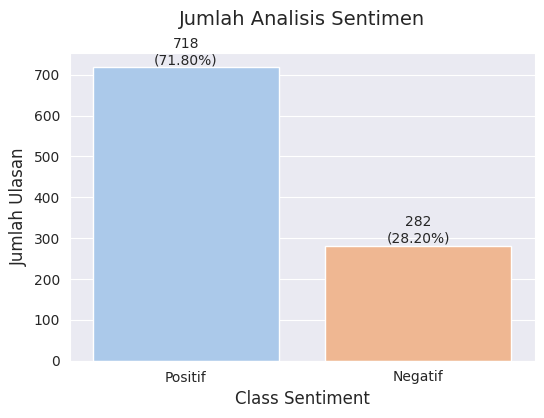

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sentiment_count = df['Sentiment'].value_counts()
sns.set_style("darkgrid")

fig, ax=plt.subplots(figsize=(6,4))
ax = sns.barplot(x=sentiment_count.index, y=sentiment_count.values, palette="pastel")
plt.title('Jumlah Analisis Sentimen', fontsize=14, pad=20)
plt.xlabel('Class Sentiment', fontsize=12)
plt.ylabel('Jumlah Ulasan', fontsize=12)

total = len(df['Sentiment'])

for i, count in enumerate(sentiment_count.values):
    percentage = f'{100 * count / total:.2f}%'
    ax.text(i, count + 0.10, f'{count}\n({percentage})', ha='center', va='bottom')

plt.show()

In [ ]:
df.to_csv('hasil_labeling_lexicon_based_googlecloud.csv', encoding='utf8', index=False);

# **MODEL ALGORITMA SUPPORT VECTOR MACHINE (SVM)**

In [ ]:
import pandas as pd

data = pd.read_csv('hasil_labeling_lexicon_based_googlecloud.csv')
data.head(20)

,"conversation_id_str,created_at",full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,steming_data,Sentiment
0,"1873942155976204370,Tue Dec 31 04:00:00 +0000 ...","""#GoogleCloud recap: 2024 edition ️ Sebelum m...",GoogleCloud recap edition Sebelum melangkah...,googlecloud recap edition sebelum melangkah...,googlecloud recap edition sebelum melangkah ke...,"['googlecloud', 'recap', 'edition', 'sebelum',...","['googlecloud', 'recap', 'edition', 'melangkah...",googlecloud recap edition lang yuk baca ulang ...,Positif
1,"1871742122673733683,Thu Dec 26 01:10:44 +0000 ...","""@AbdulRachimmks barang mewah saja ? semua pr...",AbdulRachimmks barang mewah saja semua produ...,abdulrachimmks barang mewah saja semua produ...,abdulrachimmks barang mewah saja semua produk ...,"['abdulrachimmks', 'barang', 'mewah', 'saja', ...","['abdulrachimmks', 'barang', 'mewah', 'produk'...",abdulrachimmks barang mewah produk digital ken...,Negatif
2,"1861720371793170622,Wed Nov 27 10:35:00 +0000 ...","""Simak 25+ sesi di Cloud Technical Series: Ap...",Simak sesi di Cloud Technical Series App Dev...,simak sesi di cloud technical series app dev...,simak sesi di cloud technical series app dev a...,"['simak', 'sesi', 'di', 'cloud', 'technical', ...","['simak', 'sesi', 'cloud', 'technical', 'serie...",simak sesi cloud technical series app dev amp ...,Positif
3,"1857309683171959125,Fri Nov 15 07:56:40 +0000 ...","""Inisiatif ini libat akses kepada kemudahan A...",Inisiatif ini libat akses kepada kemudahan AI...,inisiatif ini libat akses kepada kemudahan ai...,inisiatif ini libat akses kepada kemudahan ai ...,"['inisiatif', 'ini', 'libat', 'akses', 'kepada...","['inisiatif', 'libat', 'akses', 'kemudahan', '...",inisiatif libat akses mudah ai google cloud gp...,Positif
4,"1854845698593960312,Fri Nov 08 18:02:12 +0000 ...","""@ngurahbas @lynxluna gcp karena telat aja ju...",ngurahbas lynxluna gcp karena telat aja juala...,ngurahbas lynxluna gcp karena telat aja juala...,ngurahbas lynxluna gcp karena telat saja juala...,"['ngurahbas', 'lynxluna', 'gcp', 'karena', 'te...","['ngurahbas', 'lynxluna', 'gcp', 'telat', 'jua...",ngurahbas lynxluna gcp telat jual produk banya...,Positif
5,"1840754932678611193,Mon Sep 30 14:05:52 +0000 ...","""Untuk Cloud storage utama kalian bisa pakai ...",Untuk Cloud storage utama kalian bisa pakai G...,untuk cloud storage utama kalian bisa pakai g...,untuk cloud storage utama kalian bisa pakai go...,"['untuk', 'cloud', 'storage', 'utama', 'kalian...","['cloud', 'storage', 'utama', 'pakai', 'google...",cloud storage utama pakai google drivefree gb ...,Positif
6,"1835334716435947706,Sun Sep 15 15:07:49 +0000 ...","""There is fucking reason gue dukung software ...",There is fucking reason gue dukung software b...,there is fucking reason gue dukung software b...,there is fucking reason gue dukung software ba...,"['there', 'is', 'fucking', 'reason', 'gue', 'd...","['there', 'is', 'fucking', 'reason', 'gue', 'd...",there is fucking reason gue dukung software ba...,Positif
7,"1834937821276389726,Sat Sep 14 12:50:42 +0000 ...","""Google Cloud AI Study Jam #JuaraGCPS10 Baru ...",Google Cloud AI Study Jam JuaraGCPS Baru kela...,google cloud ai study jam juaragcps baru kela...,google cloud ai study jam juaragcps baru kelar...,"['google', 'cloud', 'ai', 'study', 'jam', 'jua...","['google', 'cloud', 'ai', 'study', 'jam', 'jua...",google cloud ai study jam juaragcps kelar sele...,Positif
8,"1831529943379144879,Thu Sep 05 03:09:01 +0000 ...","""Sebenernya bisa kok server pemerintah sebagu...",Sebenernya bisa kok server pemerintah sebagus...,sebenernya bisa kok server pemerintah sebagus...,sebenarnya bisa kok server pemerintah sebagus ...,"['sebenarnya', 'bisa', 'kok', 'server', 'pemer...","['server', 'pemerintah', 'sebagus', 'google', ...",server perintah bagus google amazon tinggal pa...,Positif
9,"1807335280724320318,Sun Jun 30 12:55:09 +0000 ...","""@kompascom Ya Allah microsoft kan punya prod...",kompascom Ya Allah microsoft ka

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   conversation_id_str,created_at  1000 non-null   object
 1   full_text                       1000 non-null   object
 2   cleaning                        1000 non-null   object
 3   case_folding                    1000 non-null   object
 4   normalisasi                     1000 non-null   object
 5   tokenize                        1000 non-null   object
 6   stopword removal                1000 non-null   object
 7   steming_data                    1000 non-null   object
 8   Sentiment                       1000 non-null   object
dtypes: object(9)
memory usage: 70.4+ KB


In [ ]:
df = data.dropna()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   conversation_id_str,created_at  1000 non-null   object
 1   full_text                       1000 non-null   object
 2   cleaning                        1000 non-null   object
 3   case_folding                    1000 non-null   object
 4   normalisasi                     1000 non-null   object
 5   tokenize                        1000 non-null   object
 6   stopword removal                1000 non-null   object
 7   steming_data                    1000 non-null   object
 8   Sentiment                       1000 non-null   object
dtypes: object(9)
memory usage: 70.4+ KB


**SPLITTING DATA SE**T

In [ ]:
from sklearn.model_selection import train_test_split

# Pembagian data menjadi data pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(df['steming_data'], df['Sentiment'], test_size=0.20, random_state=42)

In [ ]:
# Simpan data latih ke file
train_set = pd.DataFrame({'text': X_train, 'Sentiment': y_train})
train_set.to_csv('train_set.csv', index=False)

In [ ]:
# Simpan data uji ke file
test_set = pd.DataFrame({'text': X_test, 'Sentiment': y_test})
test_set.to_csv('test_set.csv', index=False)

In [ ]:
# Mennampilkan informasi jumlah data
print(f'Jumlah data uji: {len(X_train)}')
print(f'Jumlah data latih: {len(X_test)}')

Jumlah data uji: 800
Jumlah data latih: 200


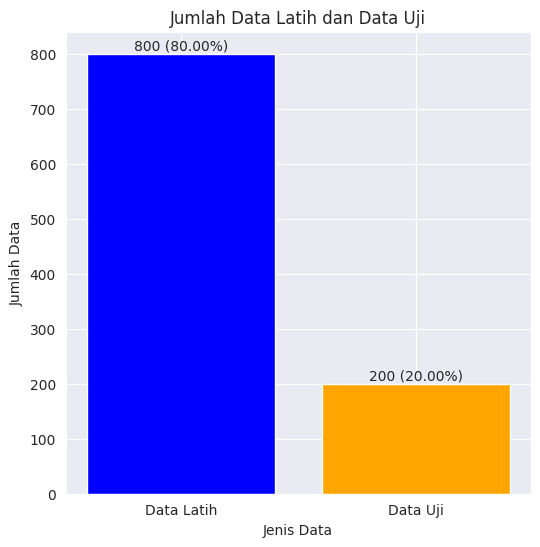

In [ ]:
import matplotlib.pyplot as plt

# Jumlah data latih dan data uji
train_size = len(X_train)
test_size = len(X_test)

# Membuat grafik batanng
plt.figure(figsize=(6, 6))
bars=plt.bar(['Data Latih', 'Data Uji'], [train_size, test_size], color=['blue', 'orange'])

# Menambahakan label untuk setiap bar(presentase persen)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.7,  f'{height} ({height / (train_size + test_size) * 100:.2f}%)', ha='center', va='bottom')

plt.title('Jumlah Data Latih dan Data Uji')
plt.xlabel('Jenis Data')
plt.ylabel('Jumlah Data')
plt.show()

**SUPPORT VECTOR MACHINE(SVM)**

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
# Mendefenisikan vectorizer
vectorizer = TfidfVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

In [ ]:
# Mesin tidak dapat membaca data dalam teks maka harus diubah ke dalam bentuk vector
# Menampilkan hasil vektorisasi
print("Matriks Vektorisasi untuk Data Uji")
print(X_train_vectorized.toarray())

# Menampilkan sebagaian kecil matriks
print("\nMatriks Vektorisasi untuk Data Latih")
print(X_test_vectorized[:5, :].toarray())

Matriks Vektorisasi untuk Data Uji
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]

Matriks Vektorisasi untuk Data Latih
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [ ]:
# Membuat dan melatih model SVM
svm = SVC(kernel='linear')
svm.fit(X_train_vectorized, y_train)

SVC(kernel='linear')

In [ ]:
# Evaluasi model
y_pred_svm = svm.predict(X_test_vectorized)

In [ ]:
# Menampilkan confusion matriks dalam angka
cm_svm = confusion_matrix(y_test, y_pred_svm)
print("Confusion Matrix (SVM):")
print(cm_svm)

Confusion Matrix (SVM):
[[ 33  23]
 [ 14 130]]


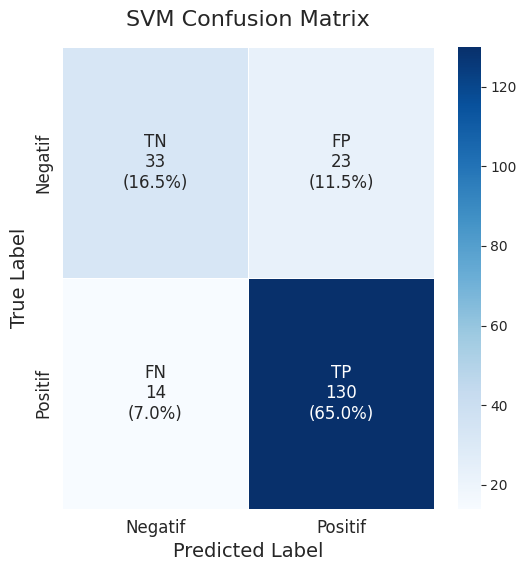

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Fungsi untuk plot confusion matrix dengan TP, TN, FP, FN
def plot_confusion_matriks(model_name, y_true, y_pred, save_path="confusion_matrix.png"):
    cm = confusion_matrix(y_true, y_pred)

    # Menentukan posisi label
    labels = np.array([["TN", "FP"], ["FN", "TP"]])
    counts = cm.astype(str)
    percent = (cm / cm.sum()) * 100
    annot = np.empty_like(cm).astype(str)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{labels[i, j]}\n{counts[i, j]}\n({percent[i, j]:.1f}%)"

    plt.figure(figsize=(6, 6))  # Membuat ukuran figure lebih besar
    ax = sns.heatmap(cm, annot=annot, fmt='', cmap='Blues',
                     xticklabels=['Negatif', 'Positif'],
                     yticklabels=['Negatif', 'Positif'],
                     linewidths=0.5, annot_kws={"size": 12})
    ax.set_title(f"{model_name} Confusion Matrix", fontsize=16, pad=15)
    ax.set_xlabel('Predicted Label', fontsize=14)
    ax.set_ylabel('True Label', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=12)

    # Menyimpan gambar ke file
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Contoh penggunaan
plot_confusion_matriks("SVM", y_test, y_pred_svm, save_path="svm_confusion_matrix.png")


In [ ]:
# Menampilkan accuracy untuk SVM
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print("SVM Accuracy:", accuracy_svm)
print("")

accuracy_svm_percentage = accuracy_svm * 100
print("SVM Accuracy :", "{:.2f}%".format(accuracy_svm_percentage))
print("")

# Menampilkan classification report untuk SVM
print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.815

SVM Accuracy : 81.50%

SVM Classification Report:
              precision    recall  f1-score   support

     Negatif       0.70      0.59      0.64        56
     Positif       0.85      0.90      0.88       144

    accuracy                           0.81       200
   macro avg       0.78      0.75      0.76       200
weighted avg       0.81      0.81      0.81       200



# **WORDCLOUD**

In [ ]:
import pandas as pd

data = pd.read_csv('hasil_labeling_lexicon_based_googlecloud.csv')
data.head()

,"conversation_id_str,created_at",full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,steming_data,Sentiment
0,"1873942155976204370,Tue Dec 31 04:00:00 +0000 ...","""#GoogleCloud recap: 2024 edition ️ Sebelum m...",GoogleCloud recap edition Sebelum melangkah...,googlecloud recap edition sebelum melangkah...,googlecloud recap edition sebelum melangkah ke...,"['googlecloud', 'recap', 'edition', 'sebelum',...","['googlecloud', 'recap', 'edition', 'melangkah...",googlecloud recap edition lang yuk baca ulang ...,Positif
1,"1871742122673733683,Thu Dec 26 01:10:44 +0000 ...","""@AbdulRachimmks barang mewah saja ? semua pr...",AbdulRachimmks barang mewah saja semua produ...,abdulrachimmks barang mewah saja semua produ...,abdulrachimmks barang mewah saja semua produk ...,"['abdulrachimmks', 'barang', 'mewah', 'saja', ...","['abdulrachimmks', 'barang', 'mewah', 'produk'...",abdulrachimmks barang mewah produk digital ken...,Negatif
2,"1861720371793170622,Wed Nov 27 10:35:00 +0000 ...","""Simak 25+ sesi di Cloud Technical Series: Ap...",Simak sesi di Cloud Technical Series App Dev...,simak sesi di cloud technical series app dev...,simak sesi di cloud technical series app dev a...,"['simak', 'sesi', 'di', 'cloud', 'technical', ...","['simak', 'sesi', 'cloud', 'technical', 'serie...",simak sesi cloud technical series app dev amp ...,Positif
3,"1857309683171959125,Fri Nov 15 07:56:40 +0000 ...","""Inisiatif ini libat akses kepada kemudahan A...",Inisiatif ini libat akses kepada kemudahan AI...,inisiatif ini libat akses kepada kemudahan ai...,inisiatif ini libat akses kepada kemudahan ai ...,"['inisiatif', 'ini', 'libat', 'akses', 'kepada...","['inisiatif', 'libat', 'akses', 'kemudahan', '...",inisiatif libat akses mudah ai google cloud gp...,Positif
4,"1854845698593960312,Fri Nov 08 18:02:12 +0000 ...","""@ngurahbas @lynxluna gcp karena telat aja ju...",ngurahbas lynxluna gcp karena telat aja juala...,ngurahbas lynxluna gcp karena telat aja juala...,ngurahbas lynxluna gcp karena telat saja juala...,"['ngurahbas', 'lynxluna', 'gcp', 'karena', 'te...","['ngurahbas', 'lynxluna', 'gcp', 'telat', 'jua...",ngurahbas lynxluna gcp telat jual produk banya...,Positif


In [ ]:
 import pandas as pd
 from wordcloud import WordCloud
 import matplotlib.pyplot as plt

 # Pisahkan dataset berdasarkan sentimen
 sentimen_negatif=data[data['Sentiment'] == 'Negatif']['steming_data'].str.cat(sep=' ')
 sentimen_positif=data[data['Sentiment'] == 'Positif']['steming_data'].str.cat(sep=' ')

In [ ]:
pip install pyspellchecker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 40.1 MB/s eta 0:00:00


In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from textblob import TextBlob
from spellchecker import SpellChecker

# Fungsi untuk memperbaiki kata yang salah ketik
def correct_typos(text):
    spell = SpellChecker(language=None)  # Membuat instance tanpa bahasa tertentu
    words = text.split()

    # Memperbaiki setiap kata yang salah ketik
    corrected_words = [spell.correction(word) for word in words]

    return " ".join(corrected_words)

# Fungsi untuk memfilter kata berdasarkan sentimen
def filter_words_by_sentiment(text, sentiment):
    # Memperbaiki typo dalam teks
    corrected_text = correct_typos(text)

    words = corrected_text.split()
    filtered_words = []

    for word in words:
        # Menghitung sentimen setiap kata
        analysis = TextBlob(word)
        polarity = analysis.sentiment.polarity

        # Memasukkan kata berdasarkan sentimen
        if sentiment == 'positive' and polarity > 0:
            filtered_words.append(word)
        elif sentiment == 'negative' and polarity < 0:
            filtered_words.append(word)

    return filtered_words

# Fungsi untuk membuat dan menampilkan WordCloud
def create_wordcloud(text, title):
    wordcloud = WordCloud(
        width=1200, height=800,    # Ukuran lebih besar untuk ketajaman lebih tinggi
        max_words=150,             # Lebih banyak kata
        background_color='white',
        colormap='viridis',
        random_state=42,
        contour_color='black',     # Tambahkan outline hitam agar lebih kontras
        contour_width=1,           # Lebih tebal untuk garis batas
        prefer_horizontal=0.5     # Lebih banyak kata horizontal
    ).generate(text)

    # Menampilkan WordCloud dengan DPI lebih tinggi untuk ketajaman
    plt.figure(figsize=(10, 7))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(title, fontsize=17)
    plt.axis('off')
    plt.tight_layout()

    # Simpan ke file PNG dengan resolusi lebih tinggi
    plt.savefig(f"{title}.png", dpi=300)
    plt.show()

# Fungsi utama untuk menggabungkan dan menampilkan kedua WordCloud
def create_combined_wordcloud(text):
    # Memfilter kata berdasarkan sentimen positif dan negatif
    positive_words = filter_words_by_sentiment(text, 'positive')
    negative_words = filter_words_by_sentiment(text, 'negative')

    # Membuat set untuk menghilangkan duplikasi dalam masing-masing sentimen
    unique_positive_words = " ".join(set(positive_words))  # Menghapus kata duplikat positif
    unique_negative_words = " ".join(set(negative_words))  # Menghapus kata duplikat negatif

    # Membuat dan menampilkan WordCloud untuk sentimen positif
    create_wordcloud(unique_positive_words, "Positive Sentiment WordCloud")

    # Membuat dan menampilkan WordCloud untuk sentimen negatif
    create_wordcloud(unique_negative_words, "Negative Sentiment WordCloud")


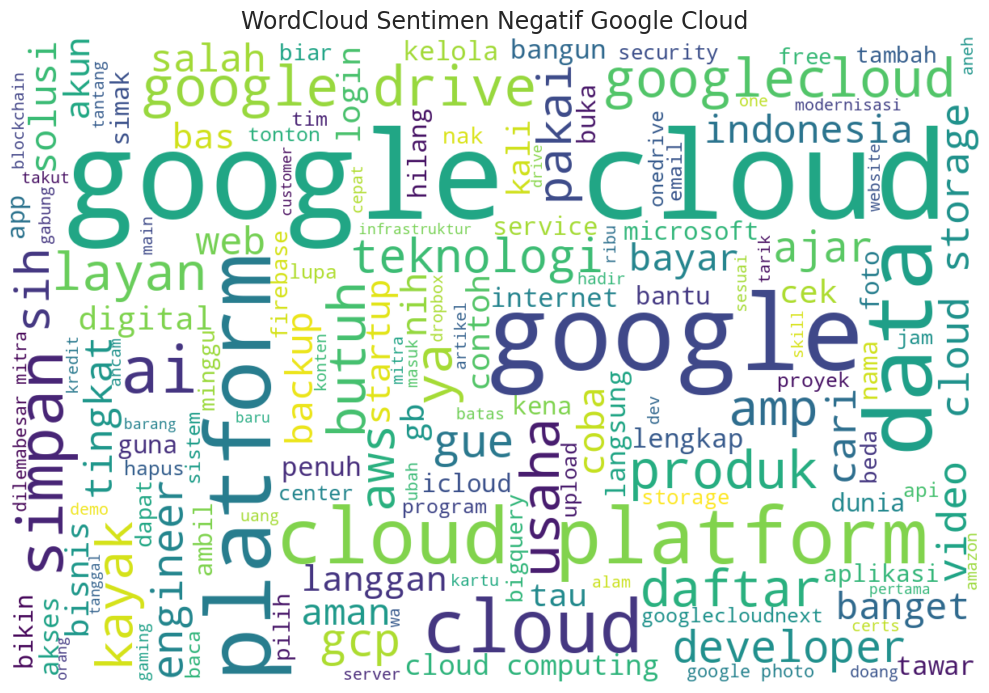

In [ ]:
create_wordcloud(sentimen_negatif, 'WordCloud Sentimen Negatif Google Cloud')


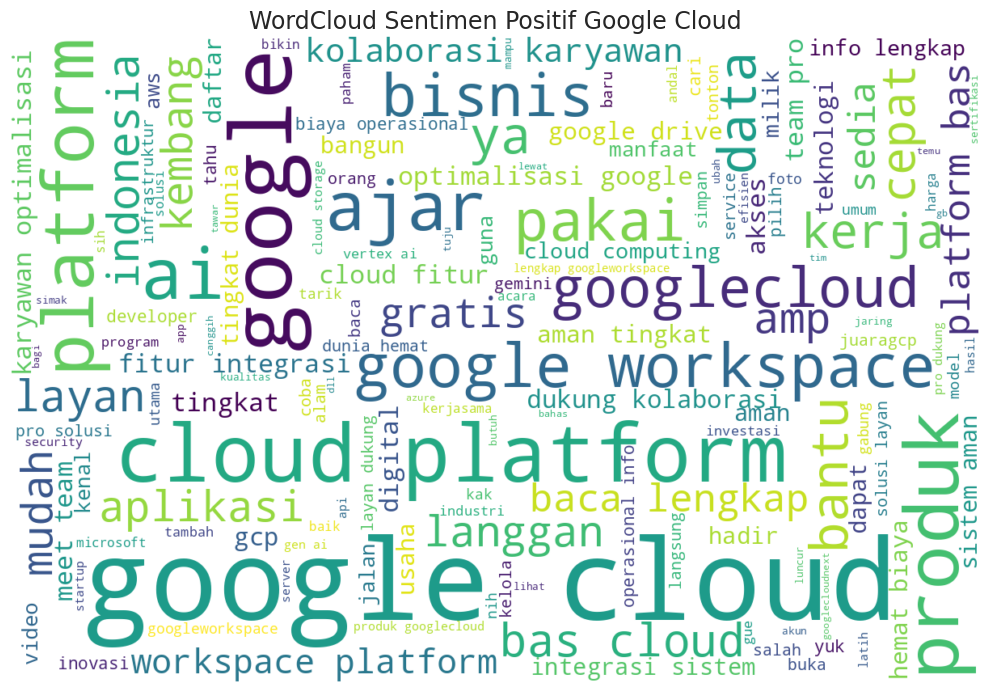

In [ ]:
create_wordcloud(sentimen_positif, 'WordCloud Sentimen Positif Google Cloud')

# **RATING**

In [ ]:
import pandas as pd

data = pd.read_csv('hasil_labeling_lexicon_based1.csv')
data.head()

,Date,Username,Rating,Review Text,cleaning,case_folding,normalisasi,tokenize,stopword removal,steming_data,Sentiment
0,2024-12-17 11:38:18,Pengguna Google,3,chat support respon lelet.,chat support respon lelet,chat support respon lelet,chat support respon lelet,"['chat', 'support', 'respon', 'lelet']","['chat', 'support', 'respon', 'lelet']",chat support respon lelet,Positif
1,2024-12-17 07:02:17,Pengguna Google,5,User friendly,User friendly,user friendly,user friendly,"['user', 'friendly']","['user', 'friendly']",user friendly,Positif
2,2024-12-17 06:58:32,Pengguna Google,5,Sangat bagus,Sangat bagus,sangat bagus,sangat bagus,"['sangat', 'bagus']",['bagus'],bagus,Positif
3,2024-12-17 05:19:30,Pengguna Google,5,Tambahkan keterangan UW di setiap saham dong m...,Tambahkan keterangan UW di setiap saham dong m...,tambahkan keterangan uw di setiap saham dong m...,tambahkan keterangan uw di setiap saham dong m...,"['tambahkan', 'keterangan', 'uw', 'di', 'setia...","['tambahkan', 'keterangan', 'uw', 'saham', 'mi...",tambah terang uw saham min profil,Positif
4,2024-12-17 04:02:49,Pengguna Google,5,Makin mantuuuullll,Makin mantuuuullll,makin mantuuuullll,makin mantap,"['makin', 'mantap']",['mantap'],mantap,Positif


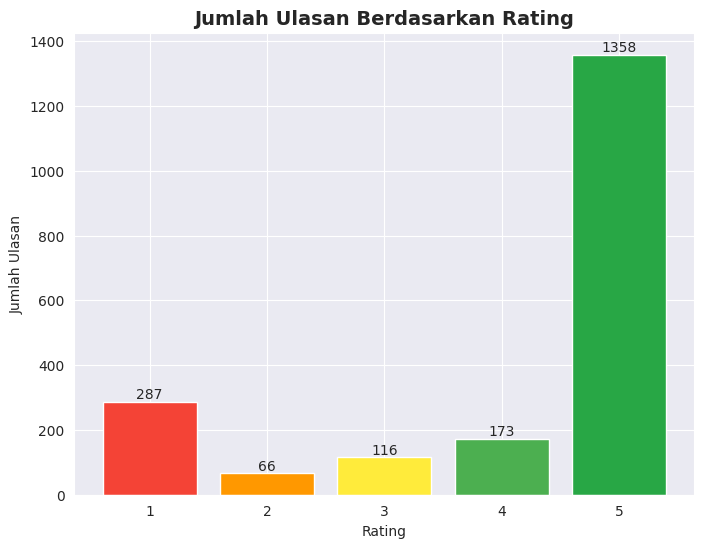

In [ ]:
import matplotlib.pyplot as plt

rating_counts = data['Rating'].value_counts()
rating_counts = rating_counts.sort_index()

colors = ['#f44336', '#ff9800', '#ffeb3b', '#4caf50', '#28a745']

plt.figure(figsize=(8, 6))
bars = plt.bar(rating_counts.index, rating_counts.values, color=colors)
plt.title('Jumlah Ulasan Berdasarkan Rating', fontsize=14, fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('Jumlah Ulasan')
plt.xticks(rating_counts.index)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.10, f'{height}', ha='center', va='bottom')

plt.show()